In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt

In [ ]:
img_height, img_width = 200,500
batch_size = 20

train_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/drive/My Drive/DataNotes/train",
    image_size = (img_height, img_width),
    batch_size = batch_size
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/drive/My Drive/DataNotes/validation",
    image_size = (img_height, img_width),
    batch_size = batch_size
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/drive/My Drive/DataNotes/test",
    image_size = (img_height, img_width),
    batch_size = batch_size
)

Found 323 files belonging to 2 classes.
Found 28 files belonging to 2 classes.
Found 32 files belonging to 2 classes.


In [ ]:
model = tf.keras.Sequential(
    [
     tf.keras.layers.Rescaling(1./255),
     tf.keras.layers.Conv2D(200, 3, activation="relu"),
     tf.keras.layers.MaxPooling2D(),
     tf.keras.layers.Conv2D(200, 3, activation="relu"),
     tf.keras.layers.MaxPooling2D(),
     tf.keras.layers.Flatten(),
     tf.keras.layers.Dense(128, activation="relu"),
     tf.keras.layers.Dense(2)
    ]
)


In [ ]:
model.compile(
    optimizer="adam",
    loss=tf.losses.SparseCategoricalCrossentropy(from_logits = True),
    metrics=['accuracy']
)

In [ ]:
history =model.fit(
    train_ds,
    validation_data = val_ds,
    epochs = 10
)

Epoch 1/10
17/17 [==============================] - 8s 357ms/step - loss: 5.2994 - accuracy: 0.6966 - val_loss: 0.4557 - val_accuracy: 0.7857
Epoch 2/10
17/17 [==============================] - 7s 352ms/step - loss: 0.2545 - accuracy: 0.9288 - val_loss: 0.4273 - val_accuracy: 0.8214
Epoch 3/10
17/17 [==============================] - 7s 349ms/step - loss: 0.0571 - accuracy: 0.9783 - val_loss: 0.1720 - val_accuracy: 0.9286
Epoch 4/10
17/17 [==============================] - 7s 352ms/step - loss: 0.0230 - accuracy: 0.9876 - val_loss: 0.2126 - val_accuracy: 0.9286
Epoch 5/10
17/17 [==============================] - 7s 343ms/step - loss: 0.0147 - accuracy: 0.9907 - val_loss: 0.2903 - val_accuracy: 0.9286
Epoch 6/10
17/17 [==============================] - 7s 344ms/step - loss: 0.0123 - accuracy: 0.9907 - val_loss: 0.1213 - val_accuracy: 0.9643
Epoch 7/10
17/17 [==============================] - 7s 356ms/step - loss: 0.0037 - accuracy: 1.0000 - val_loss: 0.1607 - val_accuracy: 0.9643
Epoch 

In [ ]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rescaling_1 (Rescaling)     (None, 200, 500, 3)       0         
                                                                 
 conv2d_2 (Conv2D)           (None, 198, 498, 200)     5600      
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 99, 249, 200)      0         
 g2D)                                                            
                                                                 
 conv2d_3 (Conv2D)           (None, 97, 247, 200)      360200    
                                                                 
 max_pooling2d_3 (MaxPoolin  (None, 48, 123, 200)      0         
 g2D)                                                            
                                                                 
 flatten_1 (Flatten)         (None, 1180800)          

In [ ]:
model.evaluate(test_ds)

2/2 [==============================] - 0s 80ms/step - loss: 0.1500 - accuracy: 0.9688


[0.14996956288814545, 0.96875]

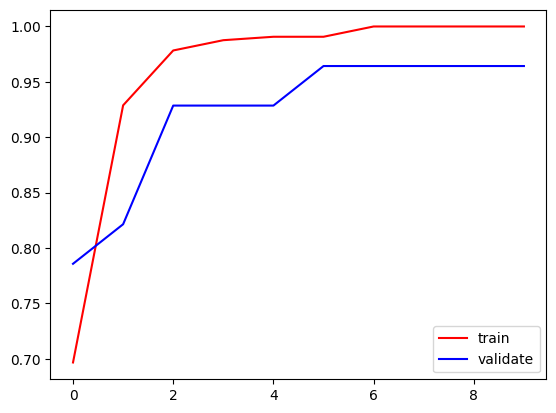

In [ ]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validate')
plt.legend()
plt.show()

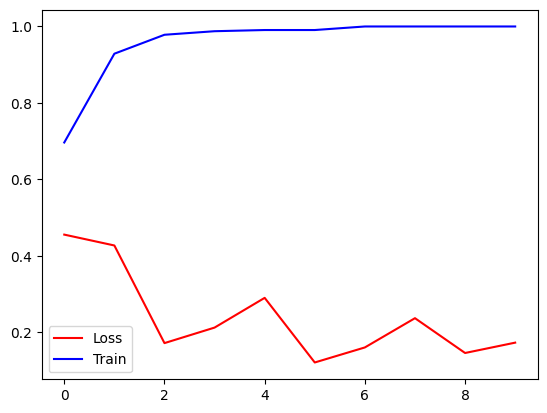

In [ ]:
import matplotlib.pyplot as plt
plt.plot(history.history['val_loss'],color='red',label='Loss')
plt.plot(history.history['accuracy'],color='blue',label='Train')
plt.legend()
plt.show()

In [ ]:
import numpy
import numpy as np
from keras.preprocessing import image
from tkinter import messagebox
def predict_note(path):
  img = image.load_img(path,target_size=(img_height,img_width))
  plt.imshow(img)
  img = image.img_to_array(img)
  img = np.expand_dims(img,axis=0)
  result =numpy.argmax(model.predict(img))
  if result== 1:
      print("Message:-","Real Indian Note Detected")
  else:
      print("Message:-", "Fake Note Detected")


1/1 [==============================] - 0s 23ms/step
Message:- Fake Note Detected


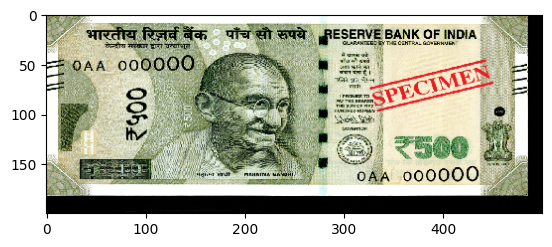

In [ ]:
predict_note("/content/drive/My Drive/DataNotes/test/Fake/f1.png")

Saving 20240514_113159.jpg to 20240514_113159.jpg
1/1 [==============================] - 0s 19ms/step
Message:- Real Indian Note Detected


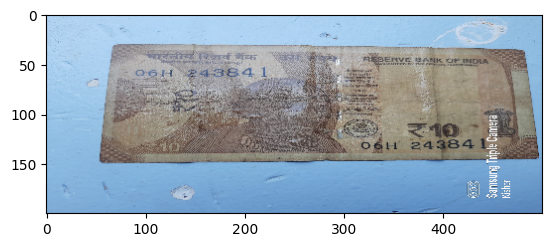

In [ ]:
from google.colab import files
import cv2
import os
uploaded = files.upload()
for fn in uploaded.keys():
  predict_note("/content/{}".format(fn))
  os.remove("/content/{}".format(fn))

In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def take_photo(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Resize the output to fit the video element.
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      // Wait for Capture to be clicked.
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)
  data = eval_js('takePhoto({})'.format(quality))
  binary = b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename

<IPython.core.display.Javascript object>

Saved to photo.jpg


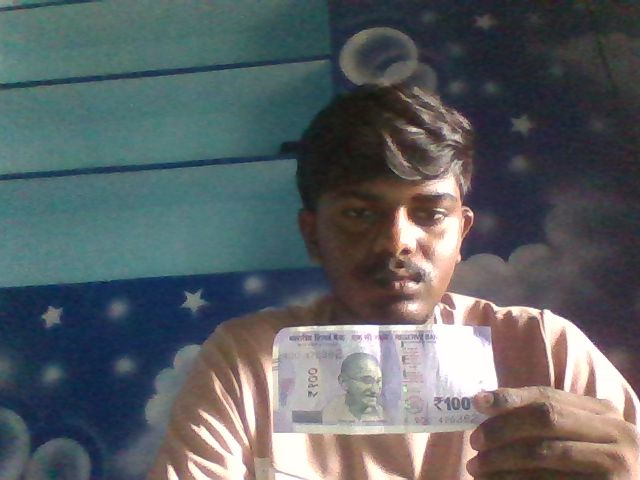

1/1 [==============================] - 0s 24ms/step
Message:- Real Indian Note Detected


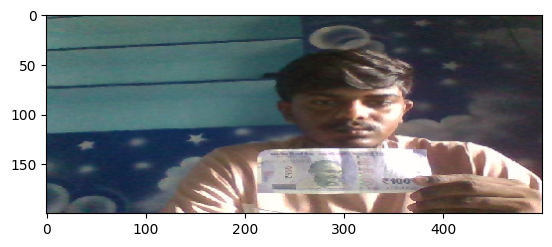

In [ ]:
from IPython.display import Image
try:
  filename = take_photo()
  print('Saved to {}'.format(filename))

  display(Image(filename))
  predict_note(filename)
except Exception as err:

  print(str(err))